# Plot signatures

This notebook generates some static plots of spatial signatures. We have a series of custom MapBox basemaps that need an API token. You will need to create and pass your own token to reproduce the figures.

_Note: This notebook requires GeoPandas 1.2 to run and dependencies listed in the import cell below. It is not reproducible in the Docker container as the other._


## Spatial Signatures

In [ ]:
import contextily
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import urbangrammar_graphics as ugg
from matplotlib_scalebar.scalebar import ScaleBar
from shapely.geometry import Point


In [2]:
sns.set(context="paper", style="ticks", rc={'patch.force_edgecolor': False})

In [3]:
spsig = gpd.read_file("/Users/martinfleis/Downloads/spatial_signatures_GB.gpkg")

In [4]:
spsig

,id,code,type,geometry
0,0_COA,COA,Countryside agriculture,"POLYGON ((62220 798500, 62110 798550, 62068.47..."
1,1_COA,COA,Countryside agriculture,"POLYGON ((63507.682 796515.169, 63471.097 7965..."
2,2_COA,COA,Countryside agriculture,"POLYGON ((65953.174 802246.172, 65950.62 80224..."
3,3_COA,COA,Countryside agriculture,"POLYGON ((67297.74 803435.8, 67220.289 803405...."
4,4_COA,COA,Countryside agriculture,"POLYGON ((75760 852670, 75700 852700, 75648.71..."
...,...,...,...,...
96699,96699_OUT,OUT,outlier,"POLYGON ((323321.005 463795.416, 323319.842 46..."
96700,96700_OUT,OUT,outlier,"POLYGON ((325929.84 1008792.061, 325927.377 10..."
96701,96701_OUT,OUT,outlier,"POLYGON ((337804.77 1013422.582, 337800.122 10..."
96702,96702_OUT,OUT,outlier,"POLYGON ((422304.27 1147826.99, 422296 1147830..."


In [5]:
def get_signature_colors(name=True):
    """
    Get a dictionary of colors mapped to signatures classes of Great Britain

    Parameters
    ----------

    name : bool
        `True` maps to names, `False` maps to string keys (e.g. `'2_1'`)

    Returns
    -------
    dict
    """
    cols = ugg.get_colormap(20, randomize=False).colors

    key = {
        "0_0": cols[16],
        "1_0": cols[15],
        "3_0": cols[9],
        "4_0": cols[12],
        "5_0": cols[21],
        "6_0": cols[8],
        "7_0": cols[4],
        "8_0": cols[18],
        "2_0": cols[6],
        "2_1": cols[23],
        "2_2": cols[19],
        "9_0": cols[7],
        "9_1": cols[3],
        "9_2": cols[22],
        "9_3": cols[0],  # outlier
        "9_4": cols[11],
        "9_5": cols[14],
        "9_6": cols[0],  # outlier
        "9_7": cols[0],  # outlier
        "9_8": cols[0],  # outlier
    }

    if name:
        types = {
            "0_0": "Countryside agriculture",
            "1_0": "Accessible suburbia",
            "3_0": "Open sprawl",
            "4_0": "Wild countryside",
            "5_0": "Warehouse/Park land",
            "6_0": "Gridded residential quarters",
            "7_0": "Urban buffer",
            "8_0": "Disconnected suburbia",
            "2_0": "Dense residential neighbourhoods",
            "2_1": "Connected residential neighbourhoods",
            "2_2": "Dense urban neighbourhoods",
            "9_0": "Local urbanity",
            "9_1": "Concentrated urbanity",
            "9_2": "Regional urbanity",
            "9_4": "Metropolitan urbanity",
            "9_5": "Hyper concentrated urbanity",
            "9_3": "outlier",
            "9_6": "outlier",
            "9_7": "outlier",
            "9_8": "outlier",
        }

        return {v: key[k] for k, v in types.items()}

    return key

In [6]:
cmap = get_signature_colors()

In [ ]:
token = "" # needs to be provided

In [9]:
spsig = spsig.to_crs(3857)

In [12]:
df = spsig

In [10]:
tyne = gpd.GeoSeries([Point(-1.6062, 54.9684)], crs=4326).to_crs(3857).buffer(35000).total_bounds

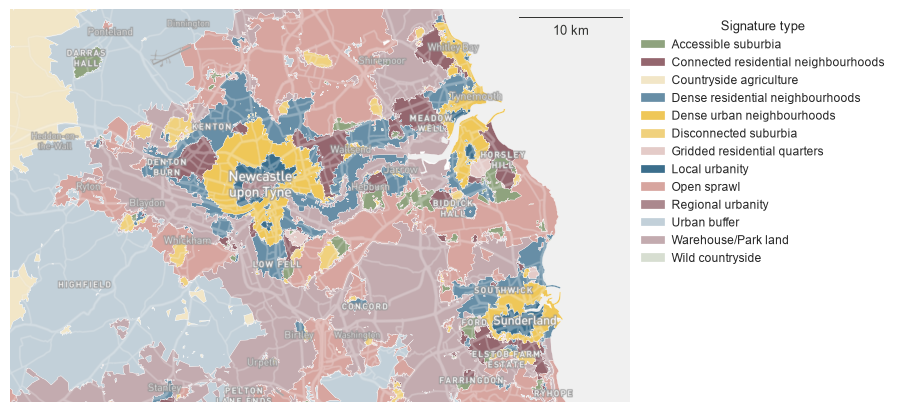

In [38]:
xm, xx, ym, yx = tyne[0]+10000, tyne[2], tyne[1]+15000, tyne[3]-17000

ax = df.cx[xm:xx, ym:yx].plot(column='type', cmap=cmap, figsize=(8, 6), zorder=1, linewidth=.2, edgecolor='w', alpha=1)

ax.set_xlim(xm, xx)
ax.set_ylim(ym, yx)

contextily.add_basemap(ax, crs=df.crs, source=ugg.get_tiles('roads', token), zorder=2, alpha=.3, attribution="")
contextily.add_basemap(ax, crs=df.crs, source=ugg.get_tiles('labels', token), zorder=3, alpha=1, attribution="")
contextily.add_basemap(ax, crs=df.crs, source=ugg.get_tiles('background', token), zorder=-1, alpha=1, attribution="")
ax.set_axis_off()

scalebar = ScaleBar(dx=1,
                    color=ugg.COLORS[0],
                    location='upper right',
                    height_fraction=0.003,
                    pad=.5,
                    frameon=False,
                    )
ax.add_artist(scalebar)


plt.legend(loc='upper left', bbox_to_anchor=(1, 1),
           handletextpad=0.5, title="Signature type", frameon=False)
plt.savefig("signatures_tyne.png", dpi=150, bbox_inches="tight")